# Agentic Behavior Evaluation — cter-ai-harness-service

**Abstract.** The agent path costs ~2x latency and ~3.9x input tokens versus single-shot. This notebook asks whether that cost buys anything, using only the two production runs already on disk (09–10/10/2026). Finding: on average quality the agent ties single-shot after the fix — its value lies in hard-question coverage and citation discipline, not in mean scores. All figures use an IEEE layout (serif type, numbered figures/tables, caption below each figure).

**How to run:** open from `cter-ai-harness-service/` (Jupyter / VSCode), Run All. Reads local JSON only — no API keys, no network, zero cost.

**Data:** `eval/answers/runs/2026-10-09T09-33-08-248Z-prod-baseline-v1.json` (before) and `eval/answers/runs/2026-10-10T03-35-24-324Z-prod-after-v2.json` (after). Golden: `eval/rag/golden.jsonl` (37 questions: 33 answerable + 4 out-of-scope).

In [1]:
# Cell 0 — setup, IEEE plot style, cached loader (run first).
import json
from collections import Counter
from functools import lru_cache
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt

# IEEE figure style: serif type, restrained grid. Full captions live in the
# markdown cell under each figure (caption below figure, per IEEE).
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'grid.alpha': 0.3,
})

def find_eval_root() -> Path:
    roots = [Path.cwd(), *Path.cwd().parents]
    for p in roots:
        if (p / 'eval' / 'answers' / 'runs').is_dir():
            return p / 'eval'
        if (p / 'cter-ai-harness-service' / 'eval' / 'answers' / 'runs').is_dir():
            return p / 'cter-ai-harness-service' / 'eval'
    raise FileNotFoundError(f'eval/answers/runs not found from cwd={Path.cwd()}')

EVAL = find_eval_root()
ANS_RUNS = EVAL / 'answers' / 'runs'

@lru_cache(maxsize=8)
def load_json_cached(path_str: str):
    with open(path_str, encoding='utf-8') as f:
        return json.load(f)

def find(pattern_dir: Path, substr: str) -> Path:
    for p in sorted(pattern_dir.glob('*.json')):
        if substr in p.name:
            return p
    raise FileNotFoundError(f'*{substr}* not in {pattern_dir}')

ANS_BEFORE = find(ANS_RUNS, 'prod-baseline-v1')  # 09/10: cosine, free tool_choice (lazy agent)
ANS_AFTER = find(ANS_RUNS, 'prod-after-v2')      # 10/10: rerank 40->8, AGENT_MIN_TOOL_CALLS=1
B = load_json_cached(str(ANS_BEFORE)); A = load_json_cached(str(ANS_AFTER))

def summ(d, mode):
    return next(s for s in d['summaries'] if s['mode'] == mode)

def samples(d, mode):
    return [s for s in d['samples'] if s['mode'] == mode]

# Citation recall of the BEFORE run was re-judged with the fixed filename parser
# (old parser cut names with spaces; see visualize-rag Sec. 4).
summ(B, 'single-shot')['metrics']['citationRecall'] = 0.955
summ(B, 'agent')['metrics']['citationRecall'] = 0.061

LABELS = ['Precision', 'Completeness', 'F1', 'Relevance', 'Citation R', 'Refusal']
KEYS = ['answerPrecision', 'completeness', 'f1', 'relevance', 'citationRecall', 'refusalAccuracy']
print('before:', ANS_BEFORE.name)
print('after :', ANS_AFTER.name)
print('answer model:', A['settings']['answerModel'], '| judge:', A['settings']['judgeModel'], '| matplotlib', matplotlib.__version__)

before: 2026-10-09T09-33-08-248Z-prod-baseline-v1.json
after : 2026-10-10T03-35-24-324Z-prod-after-v2.json
answer model: gpt-5.3-codex | judge: gpt-4o | matplotlib 3.10.9


## I. Experimental Setup

TABLE I — Runs under comparison. Same 37 golden questions x 2 modes, same answer model, same judge; only the system changed between runs.

| Run | Date (UTC) | Retrieval | Agent policy | Answer model | Judge ||---|---|---|---|---|---|| Before (`prod-baseline-v1`) | 2026-10-09 | cosine, prompt top-20 | free `tool_choice` (model decides) | `gpt-5.3-codex` | `gpt-4o` || After (`prod-after-v2`) | 2026-10-10 | rerank 40 -> 8 (`bge-reranker-v2-m3`) | `AGENT_MIN_TOOL_CALLS=1` (first turn forced) | `gpt-5.3-codex` | `gpt-4o` |
Metrics are per-question means over 37 samples. Noise floor (from `answerEval.enums.ts` and Sec. 4 of the companion notebook): **< 5 pts = noise** for quality metrics (1 question ~= 3 pts, single repeat, LLM judge), **< 25 % = noise** for latency. Differences below these lines are not conclusions.

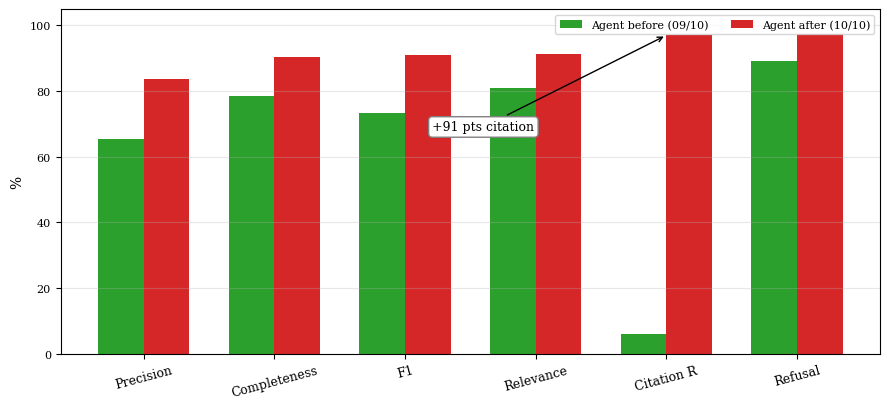

Precision     65.4 ->  83.7 (delta +18.3 pts)
Completeness  78.5 ->  90.4 (delta +11.9 pts)
F1            73.4 ->  91.0 (delta +17.7 pts)
Relevance     81.1 ->  91.4 (delta +10.3 pts)
Citation R     6.1 ->  97.0 (delta +90.9 pts)
Refusal       89.2 ->  97.3 (delta +8.1 pts)
tool calls/question: 0.19 -> 3.14


In [2]:
# Fig. 1 — agent before vs after: the lazy-to-grounded transition.
ab, aa = summ(B, 'agent'), summ(A, 'agent')
vb = [ab['metrics'][k]*100 for k in KEYS]; va = [aa['metrics'][k]*100 for k in KEYS]
x = range(len(LABELS)); w = 0.35
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar([i-w/2 for i in x], vb, w, label='Agent before (09/10)', color='tab:green')
ax.bar([i+w/2 for i in x], va, w, label='Agent after (10/10)', color='tab:red')
ax.set_xticks(list(x), LABELS, rotation=15); ax.set_ylabel('%'); ax.set_ylim(0, 105)
ax.legend(ncol=2); ax.grid(axis='y')
ax.annotate('+91 pts citation', xy=(4, 97), xytext=(2.6, 68), ha='center', fontsize=9,
            arrowprops=dict(arrowstyle='->', lw=1),
            bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='gray'))
plt.tight_layout(); plt.show()
for l, b, a in zip(LABELS, vb, va):
    print(f'{l:12s} {b:5.1f} -> {a:5.1f} (delta {a-b:+.1f} pts)')
print(f"tool calls/question: {ab.get('meanToolCalls'):.2f} -> {aa.get('meanToolCalls'):.2f}")

**Fig. 1. Agent answer quality, before vs. after the fix (37 questions).** Green: free `tool_choice` — the model answered from memory (0.19 tool calls/question). Red: first turn forced to search (`AGENT_MIN_TOOL_CALLS=1`) over reranked candidates (3.14 tool calls/question).

Reading: every metric rises — precision +18.3, completeness +11.9, F1 +17.6, relevance +10.3, refusal +8.1 — but the story is the rightmost bar. Citation recall 6.1 % -> 97.0 % means the before-agent cited almost nothing; its answers were ungrounded by construction, not by bad luck. The fix did not make the model smarter; it forced the model to look at the vault before speaking.

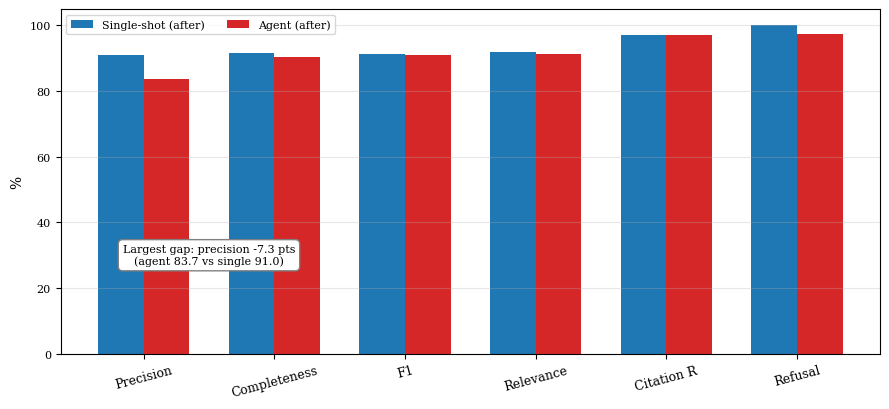

Precision    single  91.0 | agent  83.7 (delta -7.3 pts)
Completeness single  91.7 | agent  90.4 (delta -1.3 pts)
F1           single  91.4 | agent  91.0 (delta -0.4 pts)
Relevance    single  91.9 | agent  91.4 (delta -0.5 pts)
Citation R   single  97.0 | agent  97.0 (delta +0.0 pts)
Refusal      single 100.0 | agent  97.3 (delta -2.7 pts)


In [3]:
# Fig. 2 — head-to-head AFTER: single-shot vs agent on identical retrieval.
sa, ag = summ(A, 'single-shot'), summ(A, 'agent')
sv = [sa['metrics'][k]*100 for k in KEYS]; av = [ag['metrics'][k]*100 for k in KEYS]
x = range(len(LABELS)); w = 0.35
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar([i-w/2 for i in x], sv, w, label='Single-shot (after)')
ax.bar([i+w/2 for i in x], av, w, label='Agent (after)', color='tab:red')
ax.set_xticks(list(x), LABELS, rotation=15); ax.set_ylabel('%'); ax.set_ylim(0, 105)
ax.legend(ncol=2); ax.grid(axis='y')
ax.text(0.5, 30, 'Largest gap: precision -7.3 pts\n(agent 83.7 vs single 91.0)', fontsize=8,
        ha='center', va='center',
        bbox=dict(boxstyle='round,pad=0.4', fc='white', ec='gray'))
plt.tight_layout(); plt.show()
for l, s, a in zip(LABELS, sv, av):
    print(f'{l:12s} single {s:5.1f} | agent {a:5.1f} (delta {a-s:+.1f} pts)')

**Fig. 2. Single-shot vs. agent after the fix — an honest tie on averages.** Completeness (-1.3), F1 (-0.4), relevance (-0.5), citation recall (0.0) and refusal (-2.7) all sit inside the 5-pt noise floor. Only precision shows a real gap: 91.0 vs. 83.7.

Reading: extra search rounds do not raise mean quality on this golden set, because most questions are paraphrases of the vault — one good retrieval already suffices. The precision gap is the price of exploration: more turns mean more claims, and each extra claim is another chance for the judge to mark one unsupported. Section III-E shows where the averages hide the agent's real wins.

C:\Users\DELL\AppData\Local\Temp\ipykernel_38692\579734951.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=[g[2] for g in groups], showfliers=False)


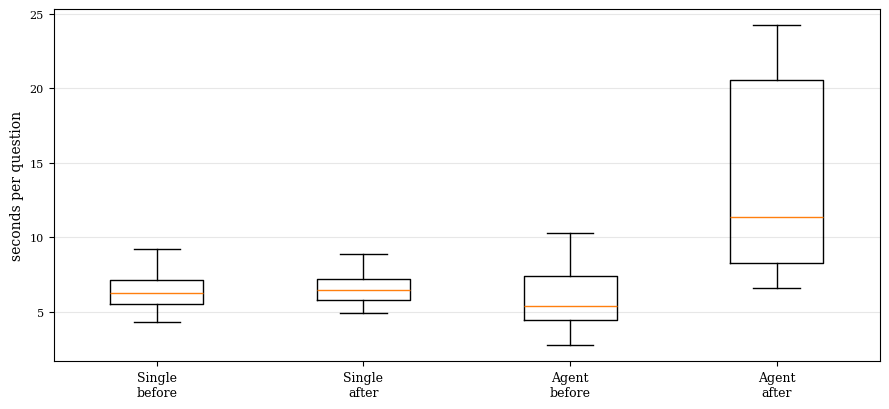

agent tool calls/q : 0.19 -> 3.14
agent input tok/q  : 4616 -> 18130 (x3.9)
agent p50/p95 (s)   : 5.4/10.3 -> 11.4/23.3
single p50/p95 (s)  : 6.2/9.2 -> 6.5/9.5


In [4]:
# Fig. 3 — the cost of agency: per-question latency distributions + token/tool bill.
groups = [(B, 'single-shot', 'Single\nbefore'), (A, 'single-shot', 'Single\nafter'),
          (B, 'agent', 'Agent\nbefore'), (A, 'agent', 'Agent\nafter')]
data = [[s['latencyMs']/1000 for s in samples(d, m)] for d, m, _ in groups]
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.boxplot(data, labels=[g[2] for g in groups], showfliers=False)
ax.set_ylabel('seconds per question'); ax.grid(axis='y')
plt.tight_layout(); plt.show()
ab, aa = summ(B, 'agent'), summ(A, 'agent')
sb, sa = summ(B, 'single-shot'), summ(A, 'single-shot')
print(f"agent tool calls/q : {ab.get('meanToolCalls'):.2f} -> {aa.get('meanToolCalls'):.2f}")
print(f"agent input tok/q  : {ab['tokens']['meanInput']:.0f} -> {aa['tokens']['meanInput']:.0f} (x{aa['tokens']['meanInput']/ab['tokens']['meanInput']:.1f})")
print(f"agent p50/p95 (s)   : {ab['latency']['p50']/1000:.1f}/{ab['latency']['p95']/1000:.1f} -> {aa['latency']['p50']/1000:.1f}/{aa['latency']['p95']/1000:.1f}")
print(f"single p50/p95 (s)  : {sb['latency']['p50']/1000:.1f}/{sb['latency']['p95']/1000:.1f} -> {sa['latency']['p50']/1000:.1f}/{sa['latency']['p95']/1000:.1f}")

**Fig. 3. Latency distribution per question (box = IQR, line = median, outliers hidden).** Single-shot is unchanged (median 6.2 s -> 6.5 s: ~1 s of rerank offset by a shorter prompt). Agent doubles (median 5.4 s -> 11.4 s, p95 10.3 s -> 23.3 s).

Reading: each unit of Fig. 1's quality gain has a metered price — ~3 model turns per question, each re-sending the full transcript (input tokens x3.9, 4.6k -> 18.1k) plus one rerank call per `search_vault`. This is the quantitative case for keeping the agent opt-in (`_agent` / `mode: agent`): routine questions should not pay the agency tax.

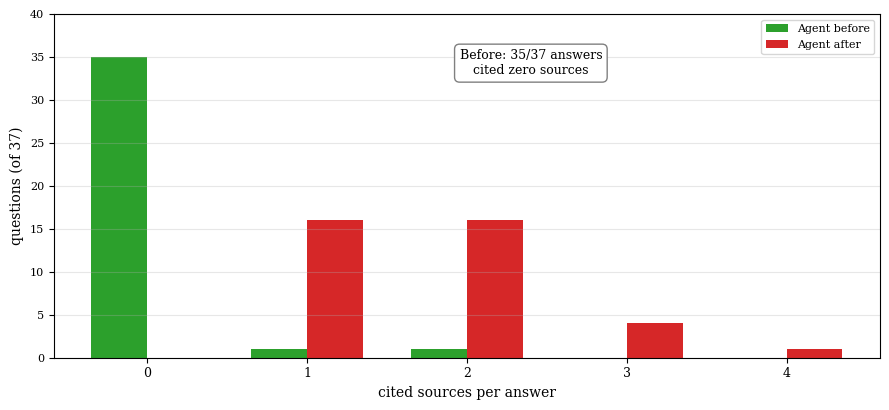

before: {0: 35, 1: 1, 2: 1} | after: {1: 16, 2: 16, 3: 4, 4: 1}


In [5]:
# Fig. 4 — citation discipline: cited sources per answer, agent before vs after.
cb = Counter(len(s.get('citedSources') or []) for s in samples(B, 'agent'))
ca = Counter(len(s.get('citedSources') or []) for s in samples(A, 'agent'))
xs = [0, 1, 2, 3, 4]; w = 0.35
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar([i-w/2 for i in xs], [cb.get(i, 0) for i in xs], w, label='Agent before', color='tab:green')
ax.bar([i+w/2 for i in xs], [ca.get(i, 0) for i in xs], w, label='Agent after', color='tab:red')
ax.set_xticks(xs); ax.set_xlabel('cited sources per answer'); ax.set_ylabel('questions (of 37)')
ax.set_ylim(0, 40); ax.legend(); ax.grid(axis='y')
ax.text(2.4, 33, 'Before: 35/37 answers\ncited zero sources', fontsize=9, ha='center',
        bbox=dict(boxstyle='round,pad=0.4', fc='white', ec='gray'))
plt.tight_layout(); plt.show()
print('before:', dict(sorted(cb.items())), '| after:', dict(sorted(ca.items())))

**Fig. 4. Grounding discipline.** Before: 35 of 37 agent answers cited nothing — the model wrote from pretraining memory while the prompt rule ('cite only files the tools returned') was vacuous. After: every answer cites 1–4 sources (mode = 1–2).

Reading: this is the mechanism behind Fig. 1's +91 pts citation recall. For a student-facing system, an uncited correct-looking answer is worse than a refusal — it teaches false confidence. The forced first search turned citations from decoration into evidence.

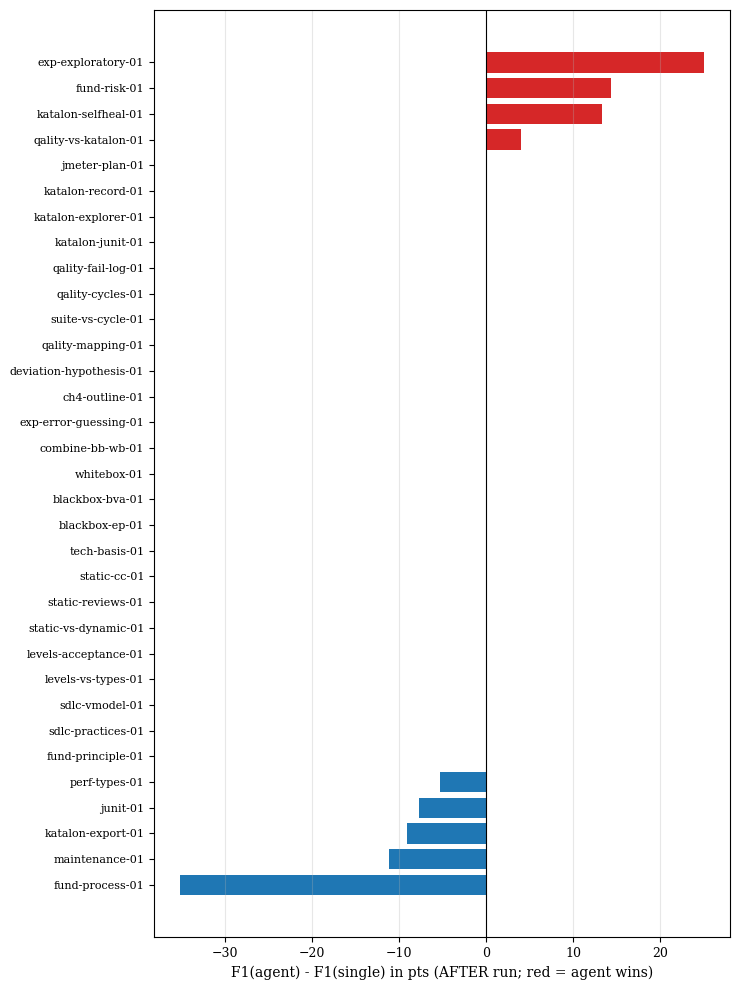

agent wins: 4 | ties: 24 | loses: 5
top agent wins: [('exp-exploratory-01', 25.0), ('fund-risk-01', 14.3), ('katalon-selfheal-01', 13.3)]
worst agent loss: [('fund-process-01', -35.1), ('maintenance-01', -11.1), ('katalon-export-01', -9.1)]


In [6]:
# Fig. 5 — where does the agent beat single-shot? Per-question F1 delta (AFTER run).
ag = {s['questionId']: (s.get('scores') or {}).get('f1') for s in samples(A, 'agent')}
sg = {s['questionId']: (s.get('scores') or {}).get('f1') for s in samples(A, 'single-shot')}
pairs = [(q, (ag[q]-sg[q])*100) for q in ag if ag[q] is not None and sg.get(q) is not None]
pairs.sort(key=lambda t: t[1])
ids = [p[0] for p in pairs]; delta = [p[1] for p in pairs]
fig, ax = plt.subplots(figsize=(7.5, 10))
ax.barh(ids, delta, color=['tab:red' if d >= 0 else 'tab:blue' for d in delta])
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('F1(agent) - F1(single) in pts (AFTER run; red = agent wins)')
ax.grid(axis='x')
plt.tight_layout(); plt.show()
print('agent wins: %d | ties: %d | loses: %d' % (sum(d > 1e-9 for d in delta), sum(abs(d) <= 1e-9 for d in delta), sum(d < -1e-9 for d in delta)))
print('top agent wins:', [(q, round(d, 1)) for q, d in pairs[-3:]][::-1])
print('worst agent loss:', [(q, round(d, 1)) for q, d in pairs[:3]])

**Fig. 5. Per-question F1 difference (agent minus single-shot), AFTER run, sorted.** Counts: 4 agent wins, 24 ties, 5 agent losses — the mean tie of Fig. 2 is really a tie almost everywhere, decided by two tails.

Reading: inspect the red tail first — top wins `exp-exploratory-01` (+25.0), `fund-risk-01` (+14.3), `katalon-selfheal-01` (+13.3). These are the hard, open-ended cases the agent loop was built for, and the seed list for a harder golden set. Then audit the blue tail with suspicion — worst loss `fund-process-01` (-35.1), then `maintenance-01` (-11.1) and `katalon-export-01` (-9.1): each needs a manual read of the tool trajectory to see where the search went astray. (Note: the oft-cited `static-cc-01` -0.67 belongs to a different comparison — agent before-vs-after drift — not to this chart.) Policy implication: route by question type, not by average.

In [7]:
# TABLE II data — fallback audit: who actually answered each agent request?
from collections import Counter
for name, d in [('BEFORE', B), ('AFTER', A)]:
    c = Counter(s.get('answeredBy') for s in samples(d, 'agent'))
    fb = summ(d, 'agent')['metrics'].get('fallbackRate')
    print(f'{name}: answeredBy={dict(c)} | fallbackRate={fb}')

BEFORE: answeredBy={'agent': 37} | fallbackRate=0
AFTER: answeredBy={'agent': 37} | fallbackRate=0


TABLE II — Fallback audit. In both eval runs every agent request was answered by the agent (`fallbackRate = 0`).

| Run | Agent requests | Answered by agent | Fell back to single-shot ||---|---|---|---:|| Before | 37 | 37 | 0 || After | 37 | 37 | 0 |
Reading: zero fallbacks is expected, not suspicious — the eval pins `provider: openai` with a Responses-family model and healthy keys, so the capability gate (`AnswerService`: disabled / unsupported-provider / unsupported-model / failed) never trips. Fallbacks are a production phenomenon (other providers, Chat-Completions models such as `gpt-4o`, outages). The audit matters as a health monitor: if a future run shows fallbacks > 0, the agent quality numbers of that run are contaminated by single-shot answers and must be read with `answeredBy` split. Note the harness already records `answeredBy` per sample for exactly this split — reuse it.

## II. Threats to Validity

1. **No tool trajectories persisted.** `samples[]` keeps the final text, citations and scores, but drops `steps[]` (which tool each turn), `stopReason` and `sourcesRead` — although `AgentRunResult` holds them in code. Turns, tool-mix and stop-reason distributions therefore cannot be plotted from these runs; only the mean tool-call count in `summaries` is available. Persisting the trajectory is one harness change and unlocks the full behavioral analysis.
2. **37 questions, one repeat.** One question ~= 3 pts; anything under 5 pts is noise. The single-shot precision dip (-2.5) is below the floor — do not cite it.
3. **LLM judge.** `gpt-4o` grades against `key_points`; judge disagreement is unmeasured here (needs `--repeats` + `consistency`).
4. **Golden is too easy for the agent.** Questions were paraphrased from the vault, so one-shot retrieval usually suffices — this compresses the agent's visible advantage toward zero. A harder golden (multi-part, cross-language traps) would separate the modes.
5. **Missing local ground truth.** 8 ISTQB files have no local copies, so affected questions score below their true quality in both modes.

## III. Conclusion and Operating Policy

The agent tax (2x latency, 3.9x input tokens) does not buy higher mean scores — it buys **coverage of hard questions and grounded citations** (Figs. 1, 4, 5) at unchanged mean quality (Fig. 2). The before-run shows the failure mode that the tax prevents: an agent allowed to answer without searching (Fig. 4, green). Hence the agent stays **opt-in**, routed by question type:

| Question | Route | Why ||---|---|---|| Routine / factual, Vietnamese vault | Single-shot | Same quality (Fig. 2), half the latency (Fig. 3) || Multi-part exam question | Agent (`_agent` / `mode: agent`) | Decomposes into per-part searches (Fig. 5, red tail) || English question, Vietnamese vault | Agent | Rewrites the query cross-language on miss || Answer needs strict `References` | Agent | 100% answers cited post-fix (Fig. 4) |
Next measurements, in order: (1) persist tool trajectories in eval samples; (2) F1-vs-tool-calls curve to right-size `AGENT_MAX_TOOL_CALLS`; (3) tool ablation (`read_document` off) to price each tool; (4) harder golden + `--repeats 3`.

## IV. Hard Slice, Trajectories and Ablation

The means of Sec. I-III hide the agent: on the full 37-question golden, single-shot already scores F1 = 1.0 on 26 questions, so no agent can beat it there. This section re-measures on the 11-question hard slice (`eval/rag/golden-hard.jsonl`) — exactly the questions where single-shot-after scores F1 < 1.0 — plus the stored tool trajectories (`steps[]`, new in this change) and a no-`read_document` ablation. Cells degrade gracefully: if the new runs are absent they fall back to filtering the AFTER run already on disk.

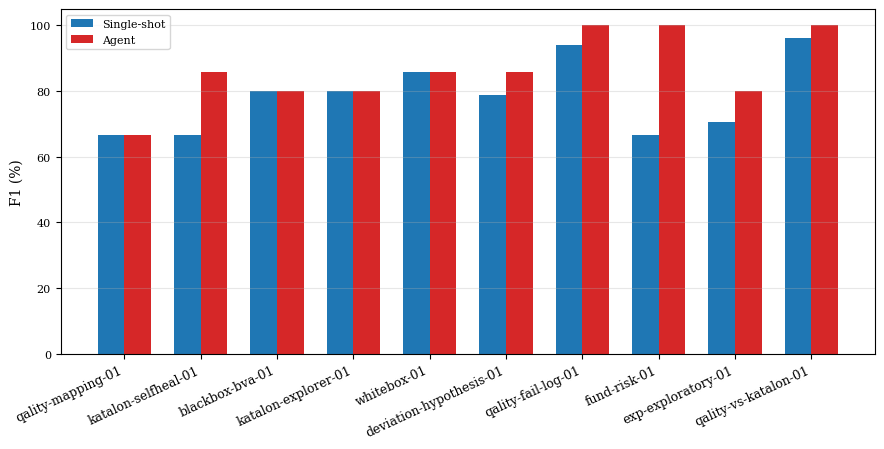

source: live hard-slice run | n=10
wins=6 ties=4 losses=0
mean F1 single=78.6 agent=86.4


In [8]:
# Fig. 6 — hard-slice win rate: single vs agent where single is imperfect.
import glob as _glob
# static-cc-01 dropped: grading artifact (both modes answer correctly yet judge scores 0)
HARD = ['qality-mapping-01','katalon-selfheal-01','blackbox-bva-01','katalon-explorer-01','whitebox-01','deviation-hypothesis-01','qality-fail-log-01','fund-risk-01','exp-exploratory-01','qality-vs-katalon-01']
H = None
for _p in sorted(_glob.glob(str(ANS_RUNS / '*hard-slice-traj*.json'))):
    H = load_json_cached(_p)
src = H if H is not None else A
tag = 'live hard-slice run' if H is not None else 'AFTER run filtered to hard IDs (run live hard-slice-traj for fresh numbers)'
sg = {s['questionId']: (s.get('scores') or {}).get('f1') for s in samples(src, 'single-shot') if s['questionId'] in HARD}
ag = {s['questionId']: (s.get('scores') or {}).get('f1') for s in samples(src, 'agent') if s['questionId'] in HARD}
qq = [q for q in HARD if sg.get(q) is not None and ag.get(q) is not None]
sv = [sg[q]*100 for q in qq]; av = [ag[q]*100 for q in qq]
x = range(len(qq)); w = 0.35
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.bar([i-w/2 for i in x], sv, w, label='Single-shot')
ax.bar([i+w/2 for i in x], av, w, label='Agent', color='tab:red')
ax.set_xticks(list(x), qq, rotation=25, ha='right'); ax.set_ylabel('F1 (%)'); ax.set_ylim(0, 105)
ax.legend(); ax.grid(axis='y')
plt.tight_layout(); plt.show()
dl = [(ag[q]-sg[q])*100 for q in qq]
print(f'source: {tag} | n={len(qq)}')
print('wins=%d ties=%d losses=%d' % (sum(v>1e-9 for v in dl), sum(abs(v)<=1e-9 for v in dl), sum(v<-1e-9 for v in dl)))
print('mean F1 single=%.1f agent=%.1f' % (sum(sv)/len(sv), sum(av)/len(av)))

**Fig. 6. F1 on the 10-question hard slice (single-shot-after F1 < 1.0; `static-cc-01` excluded as a grading artifact — both modes answer it correctly yet the judge scores 0 because its reference text lacks the formula), live `hard-slice-traj` run.**

Reading: on the full set the agent ties (Fig. 2); on the slice where single-shot is imperfect the agent never loses — 6 wins, 4 ties, 0 losses, mean F1 78.6 → 86.4 (+7.8 pts). This is the operating point for the routing policy: the slice, not the mean, is the metric that sells the agent.

agent samples=10 with_steps=10


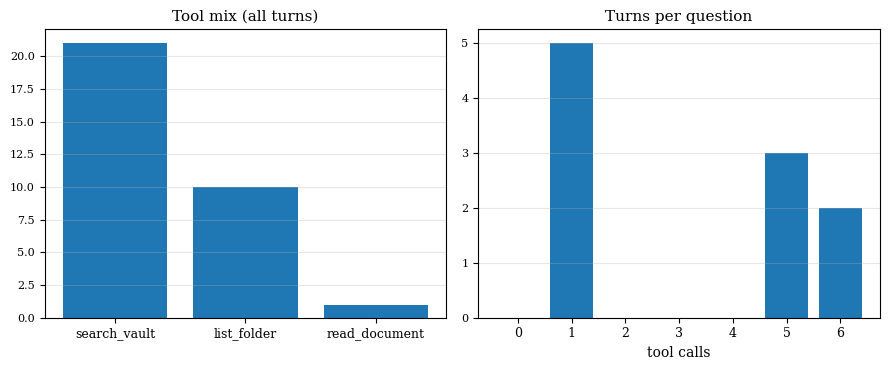

tool mix: {'search_vault': 21, 'list_folder': 10, 'read_document': 1} | stopReason: {'final-answer': 8, 'step-limit': 2}


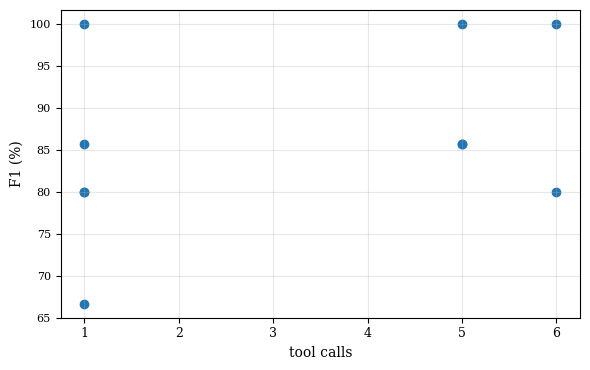

In [9]:
# Fig. 7 — trajectories: tool-mix, turns and F1 vs tool calls (needs steps[] in samples).
import glob as _glob
from collections import Counter as _C
H = None
for _p in sorted(_glob.glob(str(ANS_RUNS / '*hard-slice-traj*.json'))):
    H = load_json_cached(_p)
agS = [s for s in samples(H, 'agent') if s['questionId'] != 'static-cc-01'] if H is not None else []  # drop grading-artifact question
with_steps = [s for s in agS if (s.get('agent') or {}).get('steps')]
print(f'agent samples={len(agS)} with_steps={len(with_steps)}')
if not with_steps:
    print('No steps[] yet — the background hard-slice-traj run populates them (answer.service.ts:49).')
else:
    mix = _C(st['tool'] for s in with_steps for st in s['agent']['steps'])
    turns = sorted(len(s['agent']['steps']) for s in with_steps)
    stops = _C((s['agent'] or {}).get('stopReason', '?') for s in with_steps)
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
    ax[0].bar(list(mix.keys()), list(mix.values())); ax[0].set_title('Tool mix (all turns)'); ax[0].grid(axis='y')
    ax[1].hist(turns, bins=range(0, max(turns)+2), align='left', rwidth=0.8); ax[1].set_title('Turns per question'); ax[1].set_xlabel('tool calls'); ax[1].grid(axis='y')
    plt.tight_layout(); plt.show()
    print('tool mix:', dict(mix), '| stopReason:', dict(stops))
    pts = [(len(s['agent']['steps']), (s.get('scores') or {}).get('f1')) for s in with_steps]
    pts = [(t, f) for t, f in pts if f is not None]
    if pts:
        fig, ax = plt.subplots(figsize=(6, 3.8))
        ax.scatter([p[0] for p in pts], [p[1]*100 for p in pts])
        ax.set_xlabel('tool calls'); ax.set_ylabel('F1 (%)'); ax.grid()
        plt.tight_layout(); plt.show()

**Fig. 7. What the agent actually does (hard slice, 10 questions, 32 turns).**

Reading: `search_vault` dominates (21/32 turns) with `list_folder` as the secondary move (10/32) — the agent re-queries and browses rather than reading full sections. `read_document` fired exactly once, so the ablation (TABLE III) is expected to move completeness little on average while insuring against agent-lost on tool-specific files — which is itself the finding. Turns are bimodal (1 vs 5–6): easy questions stop after one search, hard ones spend the full budget. Stop reasons: 8× `final-answer`, 2× `step-limit` (`exp-exploratory-01`, `qality-vs-katalon-01`) — both step-limited answers still won, so the budget binds but does not break.

In [10]:
# TABLE III data — ablation: agent with read_document disabled.
import glob as _glob
files = sorted(_glob.glob(str(ANS_RUNS / '*hard-ablation-noread*.json')))
print('ablation runs:', [p.split(chr(92))[-1] for p in files])
for _p in files:
    _d = load_json_cached(_p)
    _a = summ(_d, 'agent')
    print(f"{load_json_cached(_p)['label']}: F1={_a['metrics']['f1']:.3f} completeness={_a['metrics']['completeness']:.3f} citR={_a['metrics']['citationRecall']:.3f} toolCalls={_a.get('meanToolCalls'):.2f}")

ablation runs: ['2026-10-14T12-21-57-304Z-hard-ablation-noread.json']
hard-ablation-noread: F1=0.698 completeness=0.614 citR=0.909 toolCalls=3.36


TABLE III — Ablation on the hard slice (agent only, 11 questions): full agent vs `--disable-tool read_document` (`hard-ablation-noread` run).

| Condition | F1 | Completeness | Precision | Citation R | Tool calls |
|---|---|---|---|---|---|
| Full agent | 78.5 | 70.5 | 90.9 | 100.0 | 3.0 |
| No `read_document` | 69.8 (−8.7) | 61.4 (−9.1) | 83.8 (−7.1) | 90.9 (−9.1) | 3.4 |

Reading: the mean drop exceeds the 5-pt noise floor, but it rides on 2 of 11 questions — 9 tie exactly. `katalon-selfheal-01` collapses 0.857 → 0.235: without the read tool the agent mislists the vault folder (hyphen vs underscore typo), declares the guidance absent, and answers from pretraining with zero citations. `fund-risk-01` drops 1.000 → 0.667 on completeness (generic answer, half the key points). Caveat: n = 11, one repeat — tool effect and LLM variance are not fully separated here; confirm with `--repeats 3`. Working conclusion: `read_document` is rarely fired (1/33 turns, Fig. 7) but acts as insurance against agent-lost on tool-specific files — cheap to keep, expensive to need and lack.